# Question 2 — RANSAC Line and Circle Fitting


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

RNG_SEED = 7
LINE_THRESHOLD = 1.35
LINE_MIN_INLIERS = 35
LINE_ITERATIONS = 2500
CIRCLE_THRESHOLD = 0.70
CIRCLE_MIN_INLIERS = 30
CIRCLE_ITERATIONS = 3500


In [2]:
def generate_points(seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    half_n = 50
    radius, x0_gt, y0_gt = 10.0, 2.0, 3.0

    sigma = radius / 16.0
    t = rng.uniform(0, 2*np.pi, half_n)
    noise = sigma * rng.standard_normal(half_n)
    X_circ = np.column_stack((
        x0_gt + (radius + noise)*np.cos(t),
        y0_gt + (radius + noise)*np.sin(t)
    ))

    x_line = np.linspace(-12, 12, half_n)
    y_line = -x_line + 2 + rng.standard_normal(half_n)
    X_line = np.column_stack((x_line, y_line))
    return np.vstack((X_circ, X_line)), X_circ, X_line, (x0_gt, y0_gt, radius), (-1.0, 2.0)

def line_from_two_points(p1, p2):
    delta = p2 - p1
    norm = np.linalg.norm(delta)
    if norm < 1e-12:
        return None
    tangent = delta / norm
    a, b = -tangent[1], tangent[0]
    d = a*p1[0] + b*p1[1]
    if d < 0:
        a, b, d = -a, -b, -d
    return np.array([a, b, d], dtype=float)

def line_distances(points, model):
    a, b, d = model
    return np.abs(points[:, 0]*a + points[:, 1]*b - d)

def ransac_line(points, threshold, min_inliers, iterations, rng):
    best = None
    for _ in range(iterations):
        sample = rng.choice(len(points), 2, replace=False)
        model = line_from_two_points(points[sample[0]], points[sample[1]])
        if model is None:
            continue
        inliers = np.flatnonzero(line_distances(points, model) < threshold)
        if best is None or len(inliers) > len(best[1]):
            best = (model, inliers, sample)
    if best is None or len(best[1]) < min_inliers:
        raise RuntimeError("Line RANSAC failed; adjust LINE_THRESHOLD.")
    return best

def fit_line_tls(points):
    center = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points-center, full_matrices=False)
    normal = vt[-1] / np.linalg.norm(vt[-1])
    d = float(normal @ center)
    if d < 0:
        normal, d = -normal, -d
    return np.array([normal[0], normal[1], d])

def circle_from_three_points(p1, p2, p3):
    A = 2*np.array([p2-p1, p3-p1], dtype=float)
    rhs = np.array([p2@p2-p1@p1, p3@p3-p1@p1], dtype=float)
    try:
        center = np.linalg.solve(A, rhs)
    except np.linalg.LinAlgError:
        return None
    return np.array([center[0], center[1], np.linalg.norm(center-p1)])

def circle_residuals(points, model):
    cx, cy, radius = model
    return np.abs(np.linalg.norm(points-np.array([cx, cy]), axis=1)-radius)

def ransac_circle(points, threshold, min_inliers, iterations, rng):
    best = None
    for _ in range(iterations):
        sample = rng.choice(len(points), 3, replace=False)
        model = circle_from_three_points(*points[sample])
        if model is None or model[2] <= 0 or model[2] > 1e3:
            continue
        inliers = np.flatnonzero(circle_residuals(points, model) < threshold)
        if best is None or len(inliers) > len(best[1]):
            best = (model, inliers, sample)
    if best is None or len(best[1]) < min_inliers:
        raise RuntimeError("Circle RANSAC failed; adjust CIRCLE_THRESHOLD.")
    return best

def refine_circle(points, initial):
    def objective(params):
        cx, cy, radius = params
        if radius <= 0:
            return 1e12
        residual = np.linalg.norm(points-np.array([cx, cy]), axis=1)-radius
        return np.sum(residual**2)
    result = minimize(objective, initial, method="Nelder-Mead",
                      options={"maxiter": 10000, "xatol": 1e-10})
    return result.x


In [3]:
rng = np.random.default_rng(RNG_SEED)
X, X_circ, X_line, circle_gt, line_gt = generate_points()

# Estimate line across all points.
line_sample_model, line_inliers, line_sample = ransac_line(
    X, LINE_THRESHOLD, LINE_MIN_INLIERS, LINE_ITERATIONS, rng
)
line_model = fit_line_tls(X[line_inliers])

# Remove the line consensus, then run circle RANSAC on the remnant.
keep_mask = np.ones(len(X), dtype=bool)
keep_mask[line_inliers] = False
remnant_ids = np.flatnonzero(keep_mask)
circle_sample_model, circle_local_inliers, circle_sample_local = ransac_circle(
    X[remnant_ids], CIRCLE_THRESHOLD, CIRCLE_MIN_INLIERS,
    CIRCLE_ITERATIONS, rng
)
circle_inliers = remnant_ids[circle_local_inliers]
circle_sample = remnant_ids[circle_sample_local]
circle_model = refine_circle(X[circle_inliers], circle_sample_model)

print("Line [a,b,d]:", line_model)
print("Line normal norm:", np.linalg.norm(line_model[:2]))
print("Line inliers:", len(line_inliers), "/", len(X))
print("Circle [cx,cy,r]:", circle_model)
print("Circle inliers:", len(circle_inliers), "/", len(X))


Line [a,b,d]: [0.70444533 0.70975826 1.24568475]
Line normal norm: 1.0
Line inliers: 52 / 100
Circle [cx,cy,r]: [ 1.78933556  2.96087042 10.10708063]
Circle inliers: 40 / 100


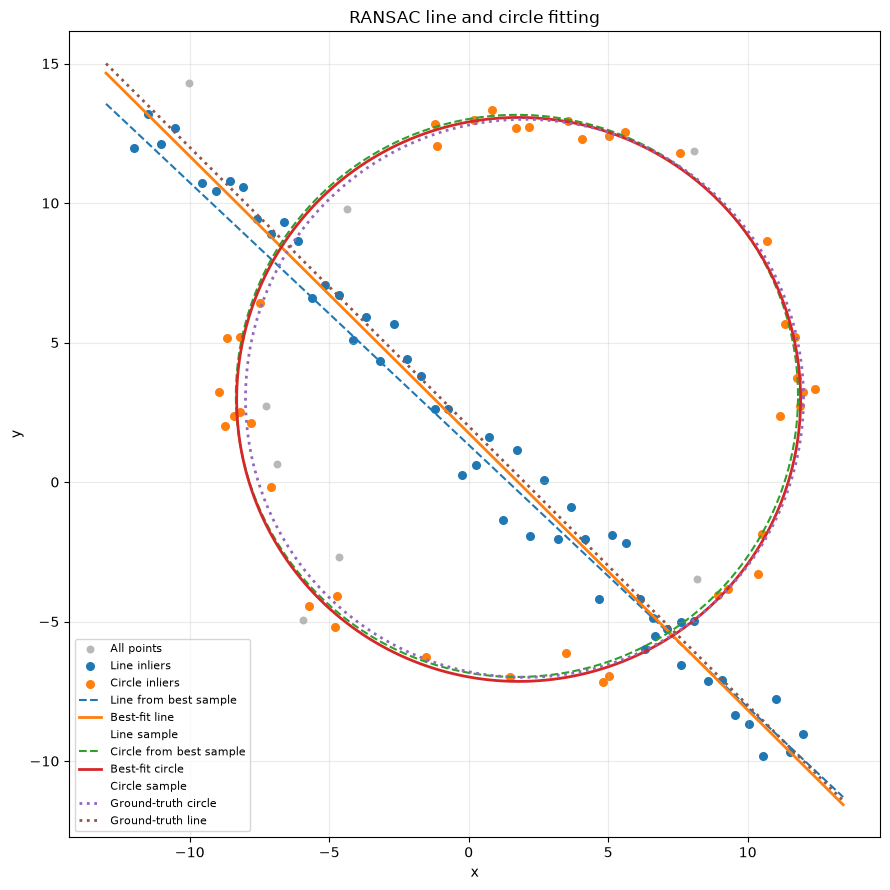

In [5]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(X[:,0], X[:,1], s=22, color="0.72", label="All points")
ax.scatter(X[line_inliers,0], X[line_inliers,1], s=30, label="Line inliers")
ax.scatter(X[circle_inliers,0], X[circle_inliers,1], s=30, label="Circle inliers")
xx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 400)

a,b,d = line_sample_model
if abs(b) > 1e-8:
    ax.plot(xx, (d-a*xx)/b, "--", label="Line from best sample")
a,b,d = line_model
if abs(b) > 1e-8:
    ax.plot(xx, (d-a*xx)/b, "-", linewidth=2, label="Best-fit line")
ax.scatter(X[line_sample,0], X[line_sample,1], s=130, marker="s",
           facecolors="none", linewidths=2, label="Line sample")

theta = np.linspace(0, 2*np.pi, 500)
cx0,cy0,r0 = circle_sample_model
ax.plot(cx0+r0*np.cos(theta), cy0+r0*np.sin(theta), "--",
        label="Circle from best sample")
cx,cy,r = circle_model
ax.plot(cx+r*np.cos(theta), cy+r*np.sin(theta), "-", linewidth=2,
        label="Best-fit circle")
ax.scatter(X[circle_sample,0], X[circle_sample,1], s=130, marker="D",
           facecolors="none", linewidths=2, label="Circle sample")

cxg,cyg,rg = circle_gt
ax.plot(cxg+rg*np.cos(theta), cyg+rg*np.sin(theta), ":",
        linewidth=2, label="Ground-truth circle")
mg,bg = line_gt
ax.plot(xx, mg*xx+bg, ":", linewidth=2, label="Ground-truth line")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("RANSAC line and circle fitting")
ax.axis("equal"); ax.grid(True, alpha=.25)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Question 2(d): What if the circle is fitted first?

If circle RANSAC is applied to the mixed point set first, the circle may capture a subset of circle points, but some line points can also fall within the radial threshold. In unfavorable samples, it may select a large or incorrect circle. Removing those consensus points can then remove genuine line points and make the later line fit less reliable. The outcome depends on the thresholds, noise, sampling and consensus sizes.